In [1]:
input_path = r'E:\2024-07-UTBenchmark-SpC\data\processed\Curio\SC14_human_lung_tumor_2'
output_path = r'E:\2024-07-UTBenchmark-SpC\data\processed\Curio\SC14_human_lung_tumor_2\harpy\sdata.zarr'

In [3]:
import os
import anndata as ad
adata = ad.read_h5ad(os.path.join(input_path, 'SC14_human_lung_tumor_2_anndata.h5ad'))

In [5]:
adata.obsm

AxisArrays with keys: X_pca, X_spatial, X_umap

In [16]:
adata.obs['numReads'].sum()

12825197

In [7]:
from curio import curio

c:\Users\julienm\miniconda3\envs\harpy\lib\site-packages\dask\dataframe\__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
c:\Users\julienm\miniconda3\envs\harpy\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [8]:
sdata = curio(input_path)

c:\Users\julienm\code\2024-07-UTBenchmark-SpC\Curio\curio.py:63: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  metrics = pd.read_csv(path / file_names[CurioKeys.METRICS_FILE], sep=r"\,", header=0)


In [11]:
sdata.tables['table'].obs

,nCount_RNA,nFeature_RNA,numReads,log10_numReads,log10_nCount_RNA,log10_nFeature_RNA,pct_rrna,percent.rp,percent.mt,nCount_SCT,nFeature_SCT,log_umi,SCT_snn_res.0.2,seurat_clusters,cluster,region,instance_id
AGCTCATCCCCATA,22.0,19,345,2.537819,1.342423,1.278754,0.045455,0.136364,0.000000,21.0,19,1.342423,7,7,7,cells,AGCTCATCCCCATA
CGGTCTATCCACCG,28.0,27,821,2.914343,1.447158,1.431364,0.000000,0.035714,0.035714,27.0,27,1.447158,24,24,24,cells,CGGTCTATCCACCG
GCTTACGGTTCCGT,40.0,38,502,2.700704,1.602060,1.579784,0.000000,0.050000,0.000000,34.0,34,1.602060,0,0,0,cells,GCTTACGGTTCCGT
TGTTGTACCATATT,52.0,44,1115,3.047275,1.716003,1.643453,0.000000,0.115385,0.019231,37.0,37,1.716003,0,0,0,cells,TGTTGTACCATATT
TTAGCGCTCTATTT,17.0,13,506,2.704151,1.230449,1.113943,0.000000,0.058824,0.000000,16.0,12,1.230449,3,3,3,cells,TTAGCGCTCTATTT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ATTAGCAGCCTCGG,10.0,9,19,1.278754,1.000000,0.954243,0.000000,0.100000,0.000000,11.0,9,1.000000,20,20,20,cells,ATTAGCAGCCTCGG
CCCCTATCGGTATA,10.0,8,21,1.322219,1.000000,0.903090,0.000000,0.100000,0.000000,12.0,8,1.000000,0,0,0,cells,CCCCTATCGGTATA
TTCTACGGACGTGC,10.0,10,17,1.230449,1.000000,1.000000,0.000000,0.200000,0.000000,10.0,10,1.000000,22,22,22,cells,TTCTACGGACGTGC
CATAGTCCCCGTGA,10.0,10,19,1.278754,1.000000,1.000000,0.000000,0.200000,0.000000,10.0,10,1.000000,0,0,0,cells,CATAGTCCCCGTGA


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' do disable this    
         behaviour.                                                                                                


c:\Users\julienm\miniconda3\envs\harpy\lib\site-packages\spatialdata\_core\_elements.py:105: UserWarning: Key `cells` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
c:\Users\julienm\miniconda3\envs\harpy\lib\site-packages\spatialdata\_core\_elements.py:125: UserWarning: Key `table` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Using the datashader reduction "mean". "max" will give an output very close to the matplotlib result.     


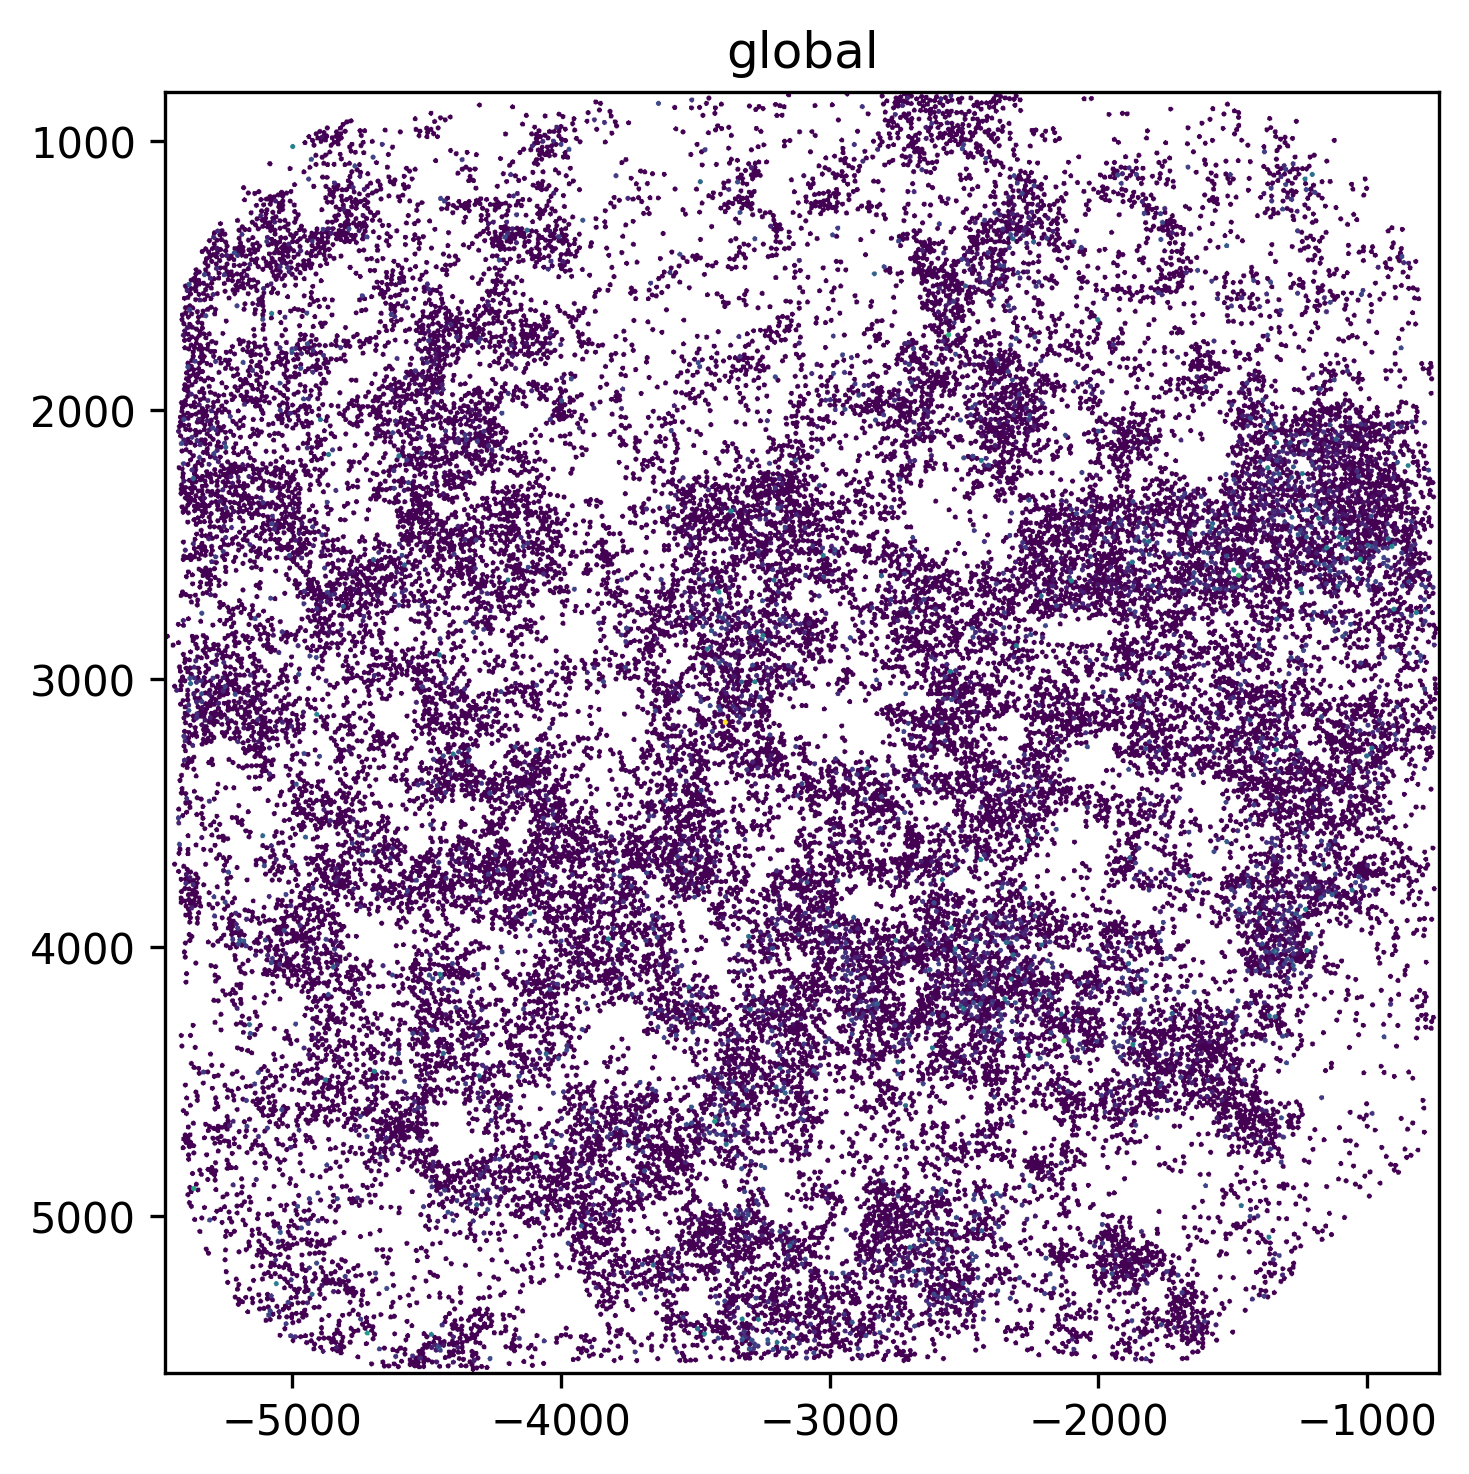

In [14]:
import spatialdata_plot
sdata.pl.render_shapes(
    element='cells', color='percent.mt'
).pl.show(
    coordinate_systems="global",
    dpi=300,
    colorbar=False,
)